<a href="https://colab.research.google.com/github/Dineshkumar-DK19/GCEE-HCL/blob/main/Phase%202%20-%20ML/UNIT%203/tamil_english_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tamil to English Neural Machine Translation

**Implementation:** Transformer built from scratch using PyTorch  
**Dataset:** OPUS-100 (`en-ta`)  
**Pretrained model weights:** Not used

## 1. Setup and configuration

In [ ]:
%pip install -q datasets tokenizers sacrebleu

import math, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

SEED       = 42
TRAIN_SIZE = 100_000
MAX_LEN    = 64
VOCAB_SIZE = 16_000

# model size
D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT = 256, 4, 3, 1024, 0.1

# training
EPOCHS, BATCH_SIZE, LR, WARMUP, LABEL_SMOOTH = 25, 128, 8e-4, 800, 0.1

random.seed(SEED);
np.random.seed(SEED);
torch.manual_seed(SEED)
device  = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("Device:", device)
if device == "cpu":
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU")

Device: cuda


## 2. Load and prepare the translation dataset

In [ ]:
from datasets import load_dataset
import re

raw = load_dataset("Helsinki-NLP/opus-100", "en-ta")

def to_pairs(ds):
    return [(x["ta"].strip(), x["en"].strip()) for x in ds["translation"]]

train_pairs = to_pairs(raw["train"].shuffle(seed=SEED).select(range(min(TRAIN_SIZE, len(raw["train"])))))
val_pairs = to_pairs(raw["validation"])
test_pairs = to_pairs(raw["test"])

# Language filtering
TAMIL_PATTERN = re.compile(r'[\u0B80-\u0BFF]')
ENGLISH_PATTERN = re.compile(r'[A-Za-z]')

def is_valid_pair(ta, en):
    return (
        len(TAMIL_PATTERN.findall(ta)) >= 2
        and len(ENGLISH_PATTERN.findall(en)) >= 2
    )

train_pairs = [p for p in train_pairs if is_valid_pair(*p)]
val_pairs = [p for p in val_pairs if is_valid_pair(*p)]
test_pairs = [p for p in test_pairs if is_valid_pair(*p)]

print("After filtering:")
print("Train:", len(train_pairs))
print("Validation:", len(val_pairs))
print("Test:", len(test_pairs))

for ta, en in train_pairs[:3]:
    print("TA:", ta)
    print("EN:", en)
    print()

README.md:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

en-ta/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  164kB            

en-ta/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-ta/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 33.3MB            

en-ta/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en-ta/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  159kB            

en-ta/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/227014 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

After filtering:
Train: 95743
Validation: 1843
Test: 1846
TA: கையெழுத்து சான்றிதழ் காலாவதியானால் எச்சரி குறைந்தபட்ச நாளை தேர்ந்தெடுத்தால் எச்சரிக்காமல் ஏற்றுக் கொள்ளவும். SPHINX அமைப்புகள் 14 நாளுக்குப் பரிந்துரைக்கப்படுகிறது.
EN: Warn If Signature Certificate Expires Select the minimum number of days the signature certificate should be valid without issuing a warning. The recommended SPHINX setting is 14 days.

TA: "நாங்கள் இறந்து, மண்ணாகவும் எலும்புகளாகவும் நாங்கள் ஆகிவிட்டாலும், மெய்யாகவே (நாங்கள் மீண்டும் உயிர்ப்பித்து) எழுப்பப்படுபவர்களா? (என்றும் கேட்கின்றனர்.)
EN: Is it ever possible that after we die and are reduced to dust and (a skeleton of) bones, we will be raised to life?

TA: எனினும், இவர்கள் உம்மை தீர்ப்பு அளிப்பவராக எப்படி ஏற்றுக் கொள்வார்கள்? இவர்களிடத்திலோ தவ்ராத் (வேத) முள்ளது. அதில் அல்லாஹ்வின் கட்டளையும் உள்ளது. எனினும் அதைப் பின்னர் புறக்கணித்து விடுகிறார்கள்;. இவர்கள் முஃமின்களே அல்லர்.
EN: And how shall they ask thee for judgement, whereas with them is the Tau

## 3. Train the tokenizer and encode sentences

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers

PAD, BOS, EOS, UNK = 0, 1, 2, 3

tok = Tokenizer(models.BPE(unk_token="<unk>"))
tok.normalizer    = normalizers.NFKC()
tok.pre_tokenizer = pre_tokenizers.Sequence([pre_tokenizers.Metaspace(), pre_tokenizers.Punctuation()])
tok.decoder       = decoders.Metaspace()
bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=["<pad>", "<s>", "</s>", "<unk>"])
tok.train_from_iterator((text for pair in train_pairs for text in pair), trainer=bpe_trainer)

VOCAB = tok.get_vocab_size()
print("Vocab size:", VOCAB)

def encode(texts):
    return [e.ids for e in tok.encode_batch(texts)]

def build(pairs):
    src = encode([p[0] for p in pairs])
    tgt = encode([p[1] for p in pairs])
    return [(s, t) for s, t in zip(src, tgt)
            if 0 < len(s) <= MAX_LEN and 0 < len(t) <= MAX_LEN]

train_data = build(train_pairs)
val_data   = build(val_pairs)
print("Training pairs after length filter:", len(train_data))

Vocab size: 16000
Training pairs after length filter: 89958


## 4. Padding and batching

In [ ]:
def pad(seqs):
    out = torch.full((len(seqs), max(len(s) for s in seqs)), PAD, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = torch.tensor(s)
    return out

def make_batches(data, batch_size, shuffle=True):
    lengths = np.array([max(len(s), len(t)) for s, t in data])
    idx = np.random.permutation(len(data)) if shuffle else np.arange(len(data))
    batches = []
    for i in range(0, len(idx), batch_size * 50):          # sort by length inside big chunks
        chunk = idx[i:i + batch_size * 50]
        chunk = chunk[np.argsort(lengths[chunk])]
        batches += [chunk[j:j + batch_size] for j in range(0, len(chunk), batch_size)]
    if shuffle:
        random.shuffle(batches)
    return batches

def get_batch(data, ids):
    src     = pad([data[i][0] + [EOS] for i in ids])
    tgt_in  = pad([[BOS] + data[i][1] for i in ids])
    tgt_out = pad([data[i][1] + [EOS] for i in ids])
    return src.to(device), tgt_in.to(device), tgt_out.to(device)

## 5. Transformer architecture

In [ ]:
def positional_encoding(max_len, d_model):
    pos = torch.arange(max_len).unsqueeze(1)
    div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe.unsqueeze(0)                      # (1, max_len, d_model)


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        self.h, self.dk = n_heads, d_model // n_heads
        self.q = nn.Linear(d_model, d_model)
        self.k = nn.Linear(d_model, d_model)
        self.v = nn.Linear(d_model, d_model)
        self.o = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, query, key, value, mask):
        B = query.size(0)
        split = lambda x, lin: lin(x).view(B, -1, self.h, self.dk).transpose(1, 2)   # (B, heads, len, dk)
        Q, K, V = split(query, self.q), split(key, self.k), split(value, self.v)
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.dk)                        # (B, heads, len_q, len_k)
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)            # hide padding / future words
        weights = self.drop(F.softmax(scores, dim=-1))
        out = (weights @ V).transpose(1, 2).contiguous().view(B, -1, self.h * self.dk)
        return self.o(out)

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
    def forward(self, x):
        return self.net(x)


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.attn, self.ff = MultiHeadAttention(d_model, n_heads, dropout), FeedForward(d_model, d_ff, dropout)
        self.n1, self.n2, self.drop = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.Dropout(dropout)

    def forward(self, x, src_mask):
        h = self.n1(x)
        x = x + self.drop(self.attn(h, h, h, src_mask))          # self-attention
        x = x + self.drop(self.ff(self.n2(x)))                   # feed-forward
        return x


class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn  = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.n1, self.n2, self.n3 = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        h = self.n1(x)
        x = x + self.drop(self.self_attn(h, h, h, tgt_mask))               # look at previous English words
        x = x + self.drop(self.cross_attn(self.n2(x), memory, memory, src_mask))   # look at the Tamil sentence
        x = x + self.drop(self.ff(self.n3(x)))
        return x

class Transformer(nn.Module):
    def __init__(self, vocab, d_model, n_heads, n_layers, d_ff, dropout, max_len=256):
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Embedding(vocab, d_model, padding_idx=PAD)
        self.register_buffer("pe", positional_encoding(max_len, d_model))
        self.drop = nn.Dropout(dropout)
        self.enc_layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.dec_layers = nn.ModuleList([DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.enc_norm, self.dec_norm = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)
        nn.init.normal_(self.embed.weight, 0, d_model ** -0.5)
        with torch.no_grad():
            self.embed.weight[PAD].zero_()

    def embed_tokens(self, x):
        return self.drop(self.embed(x) * math.sqrt(self.d_model) + self.pe[:, :x.size(1)])

    def encode(self, src):
        src_mask = (src != PAD)[:, None, None, :]                        # (B, 1, 1, src_len)
        x = self.embed_tokens(src)
        for layer in self.enc_layers:
            x = layer(x, src_mask)
        return self.enc_norm(x), src_mask

    def decode(self, tgt, memory, src_mask):
        T = tgt.size(1)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt.device))
        tgt_mask = (tgt != PAD)[:, None, None, :] & causal[None, None]   # no peeking at future words
        x = self.embed_tokens(tgt)
        for layer in self.dec_layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return F.linear(self.dec_norm(x), self.embed.weight)             # logits over the vocabulary

    def forward(self, src, tgt_in):
        memory, src_mask = self.encode(src)
        return self.decode(tgt_in, memory, src_mask)


model = Transformer(VOCAB, D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT).to(device)

## 6. Translation and evaluation functions

In [ ]:
import sacrebleu

@torch.no_grad()
def greedy_decode(src, max_len=MAX_LEN + 1):
    memory, src_mask = model.encode(src)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(max_len):
        next_tok = model.decode(ys, memory, src_mask)[:, -1].argmax(-1)       # most likely next word
        next_tok = torch.where(done, torch.full_like(next_tok, PAD), next_tok)
        ys = torch.cat([ys, next_tok[:, None]], dim=1)
        done |= next_tok == EOS
        if done.all():
            break
    return ys[:, 1:]

@torch.no_grad()
def translate(texts, batch_size=64):
    model.eval()
    outputs = []
    for i in range(0, len(texts), batch_size):
        ids = [e[:MAX_LEN] + [EOS] for e in encode(texts[i:i + batch_size])]
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            out = greedy_decode(pad(ids).to(device))
        for row in out.tolist():
            if EOS in row:
                row = row[:row.index(EOS)]
            outputs.append(tok.decode(row))
    return outputs

def bleu_score(pairs):
    hyps = translate([p[0] for p in pairs])
    return sacrebleu.corpus_bleu(hyps, [[p[1] for p in pairs]]).score

@torch.no_grad()
def validation_loss(data):
    model.eval()
    total, count = 0.0, 0
    for ids in make_batches(data, 128, shuffle=False):
        src, tgt_in, tgt_out = get_batch(data, ids)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            logits = model(src, tgt_in)
        total += F.cross_entropy(logits.float().view(-1, VOCAB), tgt_out.view(-1), ignore_index=PAD, reduction="sum").item()
        count += (tgt_out != PAD).sum().item()
    return total / count

## 7. Model training

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.98), eps=1e-9, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min((s + 1) / WARMUP, math.sqrt(WARMUP / (s + 1))))
criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTH)
scaler    = torch.amp.GradScaler("cuda", enabled=use_amp)

history, best_val = [], float("inf")
for epoch in range(1, EPOCHS + 1):
    model.train()
    start, running, steps = time.time(), 0.0, 0
    for ids in make_batches(train_data, BATCH_SIZE):
        src, tgt_in, tgt_out = get_batch(train_data, ids)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            logits = model(src, tgt_in)
        loss = criterion(logits.float().view(-1, VOCAB), tgt_out.view(-1))
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item(); steps += 1

    train_loss = running / steps
    val_loss   = validation_loss(val_data)
    val_bleu   = bleu_score(val_pairs[:300])
    history.append((train_loss, val_loss, val_bleu))
    flag = ""
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "best_model.pt")
        flag = " (saved)"
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.3f} | val loss {val_loss:.3f} | "
          f"val BLEU {val_bleu:5.2f} | {time.time() - start:.0f}s{flag}")

Epoch  1/25 | train loss 6.573 | val loss 4.768 | val BLEU  0.86 | 51s (saved)
Epoch  2/25 | train loss 4.967 | val loss 3.903 | val BLEU  4.18 | 41s (saved)
Epoch  3/25 | train loss 4.301 | val loss 3.518 | val BLEU  6.61 | 42s (saved)
Epoch  4/25 | train loss 3.927 | val loss 3.318 | val BLEU  8.21 | 40s (saved)
Epoch  5/25 | train loss 3.690 | val loss 3.188 | val BLEU 10.23 | 40s (saved)
Epoch  6/25 | train loss 3.521 | val loss 3.135 | val BLEU 11.57 | 40s (saved)
Epoch  7/25 | train loss 3.390 | val loss 3.086 | val BLEU 10.46 | 39s (saved)
Epoch  8/25 | train loss 3.288 | val loss 3.057 | val BLEU 11.23 | 39s (saved)
Epoch  9/25 | train loss 3.202 | val loss 3.026 | val BLEU 11.70 | 39s (saved)
Epoch 10/25 | train loss 3.130 | val loss 3.011 | val BLEU 12.63 | 39s (saved)
Epoch 11/25 | train loss 3.067 | val loss 2.995 | val BLEU 12.06 | 39s (saved)
Epoch 12/25 | train loss 3.015 | val loss 2.987 | val BLEU 11.03 | 40s (saved)
Epoch 13/25 | train loss 2.966 | val loss 2.986 | va

## 8. Training curve

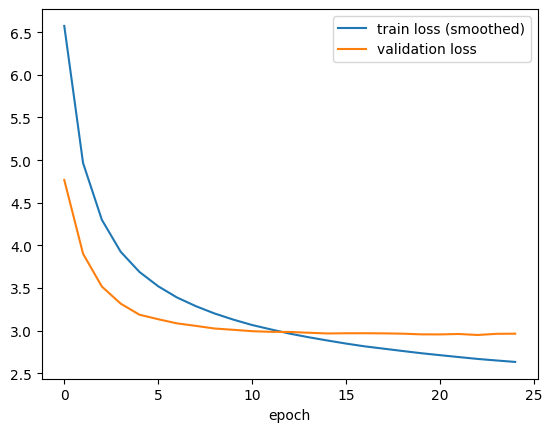

In [ ]:
import matplotlib.pyplot as plt
plt.plot([h[0] for h in history], label="train loss (smoothed)")
plt.plot([h[1] for h in history], label="validation loss")
plt.xlabel("epoch"); plt.legend(); plt.show()

## 9. Test evaluation and sample translations

In [ ]:
model.load_state_dict(torch.load("best_model.pt", map_location=device))
print("Test BLEU (first 1000 test sentences):", round(bleu_score(test_pairs[:1000]), 2))

sample = test_pairs[:8]
for (ta, en), out in zip(sample, translate([p[0] for p in sample])):
    print("TA :", ta); print("REF:", en); print("OUT:", out); print()

print(translate(["நான் பள்ளிக்கு செல்கிறேன்."]))

tok.save("tokenizer.json")

Test BLEU (first 1000 test sentences): 13.73
TA : நீளம்
REF: Length
OUT: Length:

TA : முந்தைய (_P)
REF: _Previous
OUT: Previous _Photo

TA : இந்த செயலை பூர்த்தி செய்ய அனைத்து கோப்புகளையும் ஆராய வேண்டும்.
REF: All files need to be analysed to complete this operation.
OUT: You must remove all processs and remove this file.

TA : காகிதத்தில் (எழுதப்பட்ட) ஒரு வேதத்தையே நாம் உம் மீது இறக்கி வைத்து, அதனை அவர்கள் தம் கைகளால் தொட்டுப் பார்த்தபோதிலும், "இது பகிரங்கமான சூனியத்தைத்தவிர வேறில்லை என்று அந்நிராகரிப்போர் நிச்சயமாக சொல்வார்கள்.
REF: Had We sent down upon you a book on paper, and they had touched it with their hands, those who disbelieve would have said, “This is nothing but plain magic.”
OUT: And they say: 'We sent down a sign in the Book to you, but they are in clear error, but they say, 'This is nothing but an manifest sorcery.

TA : & வலது
REF: Right
OUT: & Right

TA : ஆனால் எவர்கள் மக்களுக்கு அநியாயம் செய்து நீதமின்றி பூமியில் அட்டூழியம் செய்கிறார்களோ, அவர்கள் மீது தான் (குற